# Generic Campaign Performance Analysis

**Documented edition — original analysis logic preserved**

This notebook processes advertising campaign records across campaigns and platforms, with date validation, duplicate consolidation, impression-based incremental rates, reporting summaries, visuals, and Excel exports. The same analytical workflow can apply to multiple sectors, not solely football or horse racing.

**Input assumptions:** A workbook currently called `football_p1_extended.xlsx`, with columns such as `Month`, `Value`, `Campaign`, `Platform`, `Impressions`, `Visits`, `Incremental Visits`, `Bet`, and `Deposit`. Domain-specific outcomes may differ for other industries; this edition intentionally does not alter those names or formulas.

**How to read this notebook:** Explanatory Markdown precedes each original code cell. All original code remains intact; additional inline comments are documentation only. Outputs use the original filenames.


## Code and logic review — no computational changes

The workflow is **generic campaign-performance reporting**: import → correct dates → deduplicate → filter reporting months → platform summaries → daily and weekday performance → campaign summaries and visualisations. It can be used for different industries and campaigns **provided the same input columns and business definitions are supplied**. Existing betting/deposit metrics are specific to this example dataset, not universal metrics.

**Review observations (documented, not corrected):**

- **Date parsing:** The serial-date day/month swap is a heuristic applied to serial dates with day 1–12; it does not first choose whichever date matches `Campaign_Month`. Some records can be moved incorrectly. `Corrected` labels serial rows even if the final date was not meaningfully corrected; `Review`/`Invalid` should be investigated.
- **Duplicate consolidation:** Records with the same `Campaign`, `Platform`, and `Date_Corrected` are summed. This is appropriate only if records are additive, not repeated copies of the same event. Other columns retain the first value, which can hide discrepancies.
- **Fixed reporting scope:** Filtering, pivots and several plots are explicitly set to **August and September**; another timeframe would require edits to the original logic. Existing workbook names, exported filenames, and occasional football/other campaign labels also remain as originally coded.
- **Rate denominators:** All derived conversion/incremental rates here use **impressions** as denominator. These express attributed activity per 100 impressions and should not be interpreted automatically as user conversion probability or causal campaign lift.
- **Weekday summary:** Mean monthly rates are unweighted means of aggregated weekday rates, rather than volume-weighted whole-month rates. This is a deliberate descriptive statistic with a different interpretation.
- **Rounding:** Daily incremental volumes are rounded to integers *before* daily rates are calculated; daily rate estimates therefore reflect rounding.
- **Potential runtime dependencies:** The notebook requires the source Excel file and packages for Excel reading, Plotly and static image rendering (such as Kaleido). Some chart/export cells may fail if these dependencies are unavailable.
- **Reporting labels:** Market share refers to share of selected dataset impressions, not national or external market share. Some original narrative mentions July despite the August–September filter.

**Preservation guarantee:** No original executable statement has been altered, removed, or reordered. Only Markdown explanation and comment-only lines have been added. The notebook has not been executed against the source workbook in this review.


## Libraries and analysis setup

Imports the existing numerical, dataframe and charting dependencies. Plotly is used for interactive chart construction and static image export.


In [18]:
# Documentation: Libraries and analysis setup. Original code follows unchanged.
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from IPython.display import Image, display


## Load campaign data

Reads the existing Excel workbook and displays sample records. The hard-coded filename remains unchanged; another campaign must provide a workbook with the expected schema.


In [20]:
# Documentation: Load campaign data. Original code follows unchanged.
df = pd.read_excel("football_p1_extended.xlsx")
df.head()

,Month,Metric,Value,Platform,Clock Number,Second Length,Brand,Campaign,Impressions,% Total Impressions,...,Bet Rate,Incremental Bet,Incremental Bet Rate,Deposit,Deposit Rate,Incremental Deposit,Incremental Deposit Rate,Day,Break,Prog Type
0,2026-07-01,Day,46119,AdSmart,SRCWILH292030,30,Football,World Cup ACCA,26.48015,0.000033,...,0.000000,0.00000,0.000000,0.00000,0.000000,0.00000,0.000000,Tuesday,False,None Live Football
1,2026-07-01,Day,46119,AdSmart,SRCWILH293030,30,Football,World Cup Bet Builder,20336.75725,0.025217,...,0.258359,844.48088,0.041525,3528.04870,0.173481,567.32206,0.027896,Tuesday,False,None Live Football
2,2026-07-01,Day,46149,AdSmart,SRCWILH292030,30,Football,World Cup ACCA,12.60960,0.000016,...,0.000000,0.00000,0.000000,0.00000,0.000000,0.00000,0.000000,Thursday,False,None Live Football
3,2026-07-01,Day,46149,AdSmart,SRCWILH293030,30,Football,World Cup Bet Builder,31599.57429,0.039183,...,0.185869,945.26040,0.029914,4317.06305,0.136618,694.74042,0.021986,Thursday,False,None Live Football
4,2026-07-01,Day,46180,AdSmart,SRCWILH293030,30,Football,World Cup Bet Builder,1224.61343,0.001519,...,0.172535,33.98754,0.027754,186.75972,0.152505,30.24172,0.024695,Sunday,False,None Live Football


# Date Error Handling

This code standardises and corrects dates imported from Excel, including dates stored as serial numbers or text.

It preserves the original values, converts them into proper dates and attempts to correct dates where the day and month appear to have been reversed.

It then compares each corrected date against its campaign month, flagging records as Valid, Corrected, Review or Invalid.

Finally, it sorts the dataset chronologically and displays the results.

Important: The automatic day/month correction assumes certain Excel dates were incorrectly interpreted. It may introduce errors if that assumption is wrong. Also, dates flagged as "Corrected" are not necessarily verified as correct.

## Validate and normalise source dates

Preserves raw dates, parses Excel serials and text, conditionally swaps day/month in serial dates, and flags mismatches against campaign month. **Review flagged records before relying on date-based reporting.**


In [21]:
# Documentation: Validate and normalise source dates. Original code follows unchanged.
# Preserve original values
df["Value_Original"] = df["Value"]

# Campaign month
df["Campaign_Month"] = pd.to_datetime(
    df["Month"],
    format="%b-%y",
    errors="coerce"
)

# Identify Excel serial dates (including numeric strings)
serial_mask = (
    df["Value"].astype(str)
    .str.strip()
    .str.fullmatch(r"\d{5}(?:\.0)?")
    .fillna(False)
)
numeric = pd.to_numeric(
    df["Value"].where(serial_mask),
    errors="coerce"
)

# Convert serial values to Excel dates
excel_dates = pd.to_datetime(
    numeric,
    unit="D",
    origin="1899-12-30",
    errors="coerce"
)

# Parse the already formatted dates
text_dates = pd.to_datetime(
    df["Value"].where(~serial_mask),
    dayfirst=True,
    errors="coerce"
)

# Standard conversion
df["Date_Original"] = excel_dates.fillna(text_dates)

# Create corrected date
df["Date_Corrected"] = df["Date_Original"].copy()

# Swap day and month for identified serial dates
swap_mask = (
    serial_mask
    & excel_dates.notna()
    & excel_dates.dt.day.between(1, 12)
)

corrected = pd.to_datetime({
    "year": excel_dates.loc[swap_mask].dt.year,
    "month": excel_dates.loc[swap_mask].dt.day,
    "day": excel_dates.loc[swap_mask].dt.month
})

df.loc[swap_mask, "Date_Corrected"] = corrected

# Flag dates inconsistent with the campaign month
month_mismatch = (
    df["Date_Corrected"].dt.to_period("M")
    != df["Campaign_Month"].dt.to_period("M")
)

df["Date_Status"] = "Valid"
df.loc[serial_mask, "Date_Status"] = "Corrected"
df.loc[month_mismatch, "Date_Status"] = "Review"
df.loc[df["Date_Corrected"].isna(), "Date_Status"] = "Invalid"

# Sort by corrected date
df = df.sort_values("Date_Corrected").reset_index(drop=True)

# Inspect results
print(
    df[
        [
            "Month",
            "Value_Original",
            "Date_Original",
            "Date_Corrected",
            "Date_Status"
        ]
    ].to_string(index=False)
)

     Month Value_Original Date_Original Date_Corrected Date_Status
2026-07-01          46029    2026-01-07     2026-07-01   Corrected
2026-07-01          46029    2026-01-07     2026-07-01   Corrected
2026-07-01          46060    2026-02-07     2026-07-02   Corrected
2026-07-01          46060    2026-02-07     2026-07-02   Corrected
2026-07-01          46060    2026-02-07     2026-07-02   Corrected
2026-07-01          46088    2026-03-07     2026-07-03   Corrected
2026-07-01          46088    2026-03-07     2026-07-03   Corrected
2026-07-01          46119    2026-04-07     2026-07-04   Corrected
2026-07-01          46119    2026-04-07     2026-07-04   Corrected
2026-07-01          46119    2026-04-07     2026-07-04   Corrected
2026-07-01          46119    2026-04-07     2026-07-04   Corrected
2026-07-01          46149    2026-05-07     2026-07-05   Corrected
2026-07-01          46149    2026-05-07     2026-07-05   Corrected
2026-07-01          46149    2026-05-07     2026-07-05   Corre

## Create calendar month labels

Derives readable month names from the corrected dates, making subsequent grouping and month filtering possible.


In [22]:
# Documentation: Create calendar month labels. Original code follows unchanged.
# Extract month name (e.g. July, August, September)
df["Month_Label"] = df["Date_Corrected"].dt.month_name()

# Preview
print(df[["Date_Corrected", "Month_Label"]].head())

  Date_Corrected Month_Label
0     2026-07-01        July
1     2026-07-01        July
2     2026-07-02        July
3     2026-07-02        July
4     2026-07-02        July


# Duplicate Rows
This code identifies and merges duplicate records based on Campaign, Platform and Date.

For duplicates, it sums numerical metrics such as impressions, visits, bets and deposits, while retaining the first value for other columns.

It then recalculates all conversion rates using the combined totals, rather than averaging the original percentages.

Finally, it combines the cleaned records, sorts the dataset and displays the results.

## Consolidate duplicate observations

Uses campaign, platform and corrected date as the duplicate key, sums volume measures, retains first non-summed fields, and recomputes impression-based rates from aggregate totals.


In [24]:
# Documentation: Consolidate duplicate observations. Original code follows unchanged.
# Backup original dataset
df_original = df.copy()

# Columns identifying duplicates
group_cols = ["Campaign", "Platform", "Date_Corrected"]

# Columns to SUM
sum_cols = [
    "Impressions",
    "Visits",
    "Incremental Visits",
    "First Time Deposit",
    "Incremental First Time Deposit",
    "Bet",
    "Incremental Bet",
    "Deposit",
    "Incremental Deposit"
]

# Identify duplicate groups
duplicate_mask = df.duplicated(
    subset=group_cols,
    keep=False
)

# Separate duplicates and non-duplicates
df_duplicates = df.loc[duplicate_mask].copy()
df_unique = df.loc[~duplicate_mask].copy()

# Merge duplicate records
aggregation = {
    col: "first"
    for col in df.columns
    if col not in group_cols + sum_cols
}

aggregation.update({
    col: "sum" for col in sum_cols
})

df_merged = (
    df_duplicates
    .groupby(group_cols, as_index=False, dropna=False)
    .agg(aggregation)
)

# Replace duplicates with merged rows
df_clean = pd.concat(
    [df_unique, df_merged],
    ignore_index=True
)

# Recalculate rates
rate_mapping = {
    "Visit Rate": "Visits",
    "Incremental Visit Rate": "Incremental Visits",
    "First Time Deposit Rate": "First Time Deposit",
    "Incremental First Time Deposit Rate": "Incremental First Time Deposit",
    "Bet Rate": "Bet",
    "Incremental Bet Rate": "Incremental Bet",
    "Deposit Rate": "Deposit",
    "Incremental Deposit Rate": "Incremental Deposit"
}

for rate_col, metric_col in rate_mapping.items():
    df_clean[rate_col] = np.where(
        df_clean["Impressions"] > 0,
        df_clean[metric_col] / df_clean["Impressions"] * 100,
        np.nan
    )

# Sort and preserve original column order
df_clean = (
    df_clean[df.columns]
    .sort_values(group_cols)
    .reset_index(drop=True)
)

# Check results
print("Original rows:", len(df_original))
print("Duplicate rows identified:", duplicate_mask.sum())
print("Cleaned rows:", len(df_clean))

display(df_clean.head())

Original rows: 344
Duplicate rows identified: 137
Cleaned rows: 275


,Month,Metric,Value,Platform,Clock Number,Second Length,Brand,Campaign,Impressions,% Total Impressions,...,Incremental Deposit Rate,Day,Break,Prog Type,Value_Original,Campaign_Month,Date_Original,Date_Corrected,Date_Status,Month_Label
0,2026-09-01,Day,02/09/2026,ADSMART,SRCWILH338030,30,Football,NBTB New Season,3291.69822,0.013644,...,2.440097,Wednesday,False,None Live Football,02/09/2026,2026-09-01,2026-09-02,2026-09-02,Valid,September
1,2026-09-01,Day,03/09/2026,ADSMART,SRCWILH338030,30,Football,NBTB New Season,6119.29278,0.025365,...,1.882551,Thursday,False,None Live Football,03/09/2026,2026-09-01,2026-09-03,2026-09-03,Valid,September
2,2026-09-01,Day,04/09/2026,ADSMART,SRCWILH338030,30,Football,NBTB New Season,8502.12133,0.035242,...,1.130175,Friday,False,None Live Football,04/09/2026,2026-09-01,2026-09-04,2026-09-04,Valid,September
3,2026-09-01,Day,05/09/2026,ADSMART,SRCWILH338030,30,Football,NBTB New Season,7535.23869,0.031234,...,1.579164,Saturday,False,None Live Football,05/09/2026,2026-09-01,2026-09-05,2026-09-05,Valid,September
4,2026-09-01,Day,06/09/2026,ADSMART,SRCWILH338030,30,Football,NBTB New Season,7662.00775,0.031760,...,0.806958,Sunday,False,None Live Football,06/09/2026,2026-09-01,2026-09-06,2026-09-06,Valid,September


# Filter Months

## Apply analysis-period filter

Keeps only August and September. This fixed selection is a reporting assumption, not a generic dynamic date filter.


In [25]:
# Documentation: Apply analysis-period filter. Original code follows unchanged.
df_clean = df_clean[
    df_clean["Month_Label"].isin(["August", "September"])
].copy()

df_clean.head()

,Month,Metric,Value,Platform,Clock Number,Second Length,Brand,Campaign,Impressions,% Total Impressions,...,Incremental Deposit Rate,Day,Break,Prog Type,Value_Original,Campaign_Month,Date_Original,Date_Corrected,Date_Status,Month_Label
0,2026-09-01,Day,02/09/2026,ADSMART,SRCWILH338030,30,Football,NBTB New Season,3291.69822,0.013644,...,2.440097,Wednesday,False,None Live Football,02/09/2026,2026-09-01,2026-09-02,2026-09-02,Valid,September
1,2026-09-01,Day,03/09/2026,ADSMART,SRCWILH338030,30,Football,NBTB New Season,6119.29278,0.025365,...,1.882551,Thursday,False,None Live Football,03/09/2026,2026-09-01,2026-09-03,2026-09-03,Valid,September
2,2026-09-01,Day,04/09/2026,ADSMART,SRCWILH338030,30,Football,NBTB New Season,8502.12133,0.035242,...,1.130175,Friday,False,None Live Football,04/09/2026,2026-09-01,2026-09-04,2026-09-04,Valid,September
3,2026-09-01,Day,05/09/2026,ADSMART,SRCWILH338030,30,Football,NBTB New Season,7535.23869,0.031234,...,1.579164,Saturday,False,None Live Football,05/09/2026,2026-09-01,2026-09-05,2026-09-05,Valid,September
4,2026-09-01,Day,06/09/2026,ADSMART,SRCWILH338030,30,Football,NBTB New Season,7662.00775,0.031760,...,0.806958,Sunday,False,None Live Football,06/09/2026,2026-09-01,2026-09-06,2026-09-06,Valid,September


## Summarise performance by platform and month

Computes record counts, sums and arithmetic averages for impressions and visits by platform/month.


In [26]:
# Documentation: Summarise performance by platform and month. Original code follows unchanged.
# Summary statistics by Platform and Month
summary = (
    df_clean.groupby(["Platform", "Month", "Month_Label"])
    .agg(
        Count=("Impressions", "count"),
        Total_Impressions=("Impressions", "sum"),
        Mean_Impressions=("Impressions", "mean"),
        Total_Visits=("Visits", "sum"),
        Mean_Visits=("Visits", "mean")
    )
    .round(0)
    .reset_index()
    .sort_values(
        by=["Platform", "Month"],
        ascending=[True, False]
    )
)

print(summary.to_string(index=False))

Platform      Month Month_Label  Count  Total_Impressions  Mean_Impressions  Total_Visits  Mean_Visits
 ADSMART 2026-09-01   September     36           241248.0            6701.0       69098.0       1919.0
 ADSMART 2026-08-01      August     28           233788.0            8350.0       78636.0       2808.0
  LINEAR 2026-09-01   September     30         16673984.0          555799.0     5386347.0     179545.0
  LINEAR 2026-08-01      August     26          9107164.0          350276.0     3551071.0     136580.0
  LINEAR 2026-08-01   September      1           224085.0          224085.0      105565.0     105565.0
     VOD 2026-09-01   September     31           403817.0           13026.0      134987.0       4354.0
     VOD 2026-08-01      August     29           284632.0            9815.0      124236.0       4284.0


- Duplicate records: Rows sharing the same platform and exact month date are consolidated into one row.
- Averages: Calculated from merged totals rather than averaging existing averages. This produces correctly weighted means, assuming Count represents the number of observations.
- Month labels: Regenerated from the actual dates, avoiding inconsistencies between the month date and its label.
- No filtering: This code does not filter by Metric = Day or any other value.

## Reconcile monthly summary records

Regroups platform and month, recomputes per-record means from totals and record counts, and regenerates month labels.


In [37]:
# Documentation: Reconcile monthly summary records. Original code follows unchanged.
# Correct month labels and merge duplicate records
summary_merged = (
    summary
    .assign(
        Month=pd.to_datetime(summary["Month"])
    )
    .groupby(["Platform", "Month"], as_index=False)
    .agg(
        Count=("Count", "sum"),
        Total_Impressions=("Total_Impressions", "sum"),
        Total_Visits=("Total_Visits", "sum")
    )
)

# Recalculate means using merged totals
summary_merged["Mean_Impressions"] = (
    summary_merged["Total_Impressions"] / summary_merged["Count"]
).round(2)

summary_merged["Mean_Visits"] = (
    summary_merged["Total_Visits"] / summary_merged["Count"]
).round(2)

# Recreate month labels from actual dates
summary_merged["Month_Label"] = (
    summary_merged["Month"].dt.strftime("%B")
)

# Sort results
summary_merged = summary_merged.sort_values(
    by=["Platform", "Month"],
    ascending=[True, False]
)

display(summary_merged)

,Platform,Month,Count,Total_Impressions,Total_Visits,Mean_Impressions,Mean_Visits,Month_Label
1,ADSMART,2026-09-01,36,241248.0,69098.0,6701.33,1919.39,September
0,ADSMART,2026-08-01,28,233788.0,78636.0,8349.57,2808.43,August
3,LINEAR,2026-09-01,30,16673984.0,5386347.0,555799.47,179544.90,September
2,LINEAR,2026-08-01,27,9331249.0,3656636.0,345601.81,135430.96,August
5,VOD,2026-09-01,31,403817.0,134987.0,13026.35,4354.42,September
4,VOD,2026-08-01,29,284632.0,124236.0,9814.90,4284.00,August


## Calculate impression share and readable volume labels

Calculates each platform-month share of all selected impressions, formats large values, and selects reporting fields. This is **share of campaign impressions**, not share of the broader advertising market.


In [28]:
# Documentation: Calculate impression share and readable volume labels. Original code follows unchanged.
# Calculate market share across all impressions
total_impressions = summary_merged["Total_Impressions"].sum()

summary_merged["Total Impressions Market Share (%)"] = (
    summary_merged["Total_Impressions"] / total_impressions * 100
).round(2)

# Format numbers into K and M
def format_number(x):
    if x >= 1_000_000:
        return f"{x/1_000_000:.1f}M"
    elif x >= 1_000:
        return f"{x/1_000:.1f}K"
    return str(x)

# Create formatted columns
summary_merged["Impressions_Formatted"] = (
    summary_merged["Total_Impressions"].apply(format_number)
)

summary_merged["Visits_Formatted"] = (
    summary_merged["Total_Visits"].apply(format_number)
)

# Sort and select columns
summary_merged = (
    summary_merged[
        [
            "Platform",
            "Month",
            "Month_Label",
            "Total_Impressions",
            "Impressions_Formatted",
            "Total_Visits",
            "Visits_Formatted",
            "Total Impressions Market Share (%)"
        ]
    ]
    .sort_values(["Platform", "Month"])
    .reset_index(drop=True)
)

display(summary_merged)

,Platform,Month,Month_Label,Total_Impressions,Impressions_Formatted,Total_Visits,Visits_Formatted,Total Impressions Market Share (%)
0,ADSMART,2026-08-01,August,233788.0,233.8K,78636.0,78.6K,0.86
1,ADSMART,2026-09-01,September,241248.0,241.2K,69098.0,69.1K,0.89
2,LINEAR,2026-08-01,August,9331249.0,9.3M,3656636.0,3.7M,34.35
3,LINEAR,2026-09-01,September,16673984.0,16.7M,5386347.0,5.4M,61.37
4,VOD,2026-08-01,August,284632.0,284.6K,124236.0,124.2K,1.05
5,VOD,2026-09-01,September,403817.0,403.8K,134987.0,135.0K,1.49


## Build cross-month platform comparison

Standardises platform names and pivots impressions/visits for August and September, then calculates cross-month totals and impression shares.


In [29]:
# Documentation: Build cross-month platform comparison. Original code follows unchanged.
# Standardise platform names
summary_merged["Platform"] = (
    summary_merged["Platform"].str.upper().str.strip()
)

# Pivot monthly impressions and visits
platform_summary = summary_merged.pivot_table(
    index="Platform",
    columns="Month_Label",
    values=["Total_Impressions", "Total_Visits"],
    aggfunc="sum",
    fill_value=0
)

# Order months
month_order = ["August", "September"]

platform_summary = platform_summary.reindex(
    columns=month_order,
    level=1,
    fill_value=0
)

# Flatten column names
platform_summary.columns = [
    f"{month}_{'Impressions' if metric == 'Total_Impressions' else 'Visits'}"
    for metric, month in platform_summary.columns
]

# Ensure all month columns exist
for month in month_order:
    for metric in ["Impressions", "Visits"]:
        col = f"{month}_{metric}"
        if col not in platform_summary.columns:
            platform_summary[col] = 0

# Calculate total impressions and visits
platform_summary["Total_Impressions"] = platform_summary[
    [f"{month}_Impressions" for month in month_order]
].sum(axis=1)

platform_summary["Total_Visits"] = platform_summary[
    [f"{month}_Visits" for month in month_order]
].sum(axis=1)

# Format numbers
def format_number(value):
    if value >= 1_000_000:
        return f"{value / 1_000_000:.1f}M"
    if value >= 1_000:
        return f"{value / 1_000:.1f}K"
    return str(value)

platform_summary["Impressions_Formatted"] = (
    platform_summary["Total_Impressions"].apply(format_number)
)

platform_summary["Visits_Formatted"] = (
    platform_summary["Total_Visits"].apply(format_number)
)

# Calculate overall impression market share
platform_summary["Total Impressions Market Share (%)"] = (
    platform_summary["Total_Impressions"]
    / platform_summary["Total_Impressions"].sum()
    * 100
).round(2)

# Order output columns
ordered_columns = []

for month in month_order:
    ordered_columns.extend([
        f"{month}_Impressions",
        f"{month}_Visits"
    ])

ordered_columns.extend([
    "Total_Impressions",
    "Total_Visits",
    "Impressions_Formatted",
    "Visits_Formatted",
    "Total Impressions Market Share (%)"
])

# Reset index and display
platform_summary = (
    platform_summary[ordered_columns]
    .reset_index()
)

display(platform_summary)

,Platform,August_Impressions,August_Visits,September_Impressions,September_Visits,Total_Impressions,Total_Visits,Impressions_Formatted,Visits_Formatted,Total Impressions Market Share (%)
0,ADSMART,233788.0,78636.0,241248.0,69098.0,475036.0,147734.0,475.0K,147.7K,1.75
1,LINEAR,9331249.0,3656636.0,16673984.0,5386347.0,26005233.0,9042983.0,26.0M,9.0M,95.72
2,VOD,284632.0,124236.0,403817.0,134987.0,688449.0,259223.0,688.4K,259.2K,2.53


## Export platform comparison

Writes the existing formatted platform summary to Excel using the original filename.


In [23]:
# Documentation: Export platform comparison. Original code follows unchanged.
# Export
platform_summary.to_excel(
    "Football_Campaign_Monthly_Summary_Impressions.xlsx",
    index=False
)

# Daily Campaign Performance

## Aggregate incremental activity by calendar date

Sums impressions, visits and incremental metrics across all selected platforms/campaigns, rounds the incremental volumes, and computes rates as percentages of impressions.


In [30]:
# Documentation: Aggregate incremental activity by calendar date. Original code follows unchanged.
# ==========================================
# 1. Aggregate daily metrics - All Platforms
# ==========================================

incremental_summary = (
    df_clean.groupby("Date_Corrected", as_index=False)
    .agg({
        "Impressions": "sum",
        "Visits": "sum",
        "Incremental Visits": "sum",
        "Incremental Deposit": "sum",
        "Incremental Bet": "sum"
    })
    .sort_values("Date_Corrected")
)

# ==========================================
# 2. Round incremental metrics - 0 decimals
# ==========================================

round_columns = [
    "Incremental Visits",
    "Incremental Deposit",
    "Incremental Bet"
]

incremental_summary[round_columns] = (
    incremental_summary[round_columns]
    .round(0)
    .astype(int)
)

# ==========================================
# 3. Recalculate daily incremental rates
# ==========================================

# Avoid division by zero
impressions = incremental_summary["Impressions"].replace(0, np.nan)

incremental_summary["Incremental Visit Rate_Daily"] = (
    incremental_summary["Incremental Visits"] / impressions * 100
)

incremental_summary["Incremental Deposit Rate_Daily"] = (
    incremental_summary["Incremental Deposit"] / impressions * 100
)

incremental_summary["Incremental Bet Rate_Daily"] = (
    incremental_summary["Incremental Bet"] / impressions * 100
)

# ==========================================
# 4. Round daily rates - 2 decimal places
# ==========================================

rate_columns = [
    "Incremental Visit Rate_Daily",
    "Incremental Deposit Rate_Daily",
    "Incremental Bet Rate_Daily"
]

incremental_summary[rate_columns] = (
    incremental_summary[rate_columns].round(2)
)

# ==========================================
# 5. Display final dataset
# ==========================================

display(incremental_summary)

,Date_Corrected,Impressions,Visits,Incremental Visits,Incremental Deposit,Incremental Bet,Incremental Visit Rate_Daily,Incremental Deposit Rate_Daily,Incremental Bet Rate_Daily
0,2026-08-03,7.643009e+05,155018.36323,80138,11078,15153,10.49,1.45,1.98
1,2026-08-04,3.414398e+05,75394.40104,38756,6184,5002,11.35,1.81,1.46
2,2026-08-05,3.601564e+05,72157.25570,36224,5105,5616,10.06,1.42,1.56
3,2026-08-06,3.280533e+05,92759.84792,47766,6313,6904,14.56,1.92,2.10
4,2026-08-07,3.507602e+05,85268.61742,44219,6134,7496,12.61,1.75,2.14
5,2026-08-08,6.036822e+05,198812.53950,104710,14256,17228,17.35,2.36,2.85
6,2026-08-09,3.915677e+05,121919.88430,63343,8935,9978,16.18,2.28,2.55
7,2026-08-10,3.306914e+05,90257.86010,46646,6675,6898,14.11,2.02,2.09
8,2026-08-11,3.139003e+05,103522.80593,53549,7764,7938,17.06,2.47,2.53
9,2026-08-12,3.339279e+05,109889.15293,56558,8538,8930,16.94,2.56,2.67


## Export daily performance

Saves the daily aggregated incremental volume and rate table using the existing output filename.


In [36]:
# Documentation: Export daily performance. Original code follows unchanged.
# Export
# Convert dates to DD/MM/YYYY format
# incremental_summary["Date_Corrected"] = (
#    pd.to_datetime(incremental_summary["Date_Corrected"])
#    .dt.strftime("%d/%m/%Y")
# )

# display(incremental_summary)

incremental_summary.to_excel(
    "football_daily_incremental_rates.xlsx",
    index=False
)

## Visualise daily volumes and rates

Builds the existing daily chart to compare incremental activity volumes and rates. Chart labels and colours are presentation settings, not modelling changes.


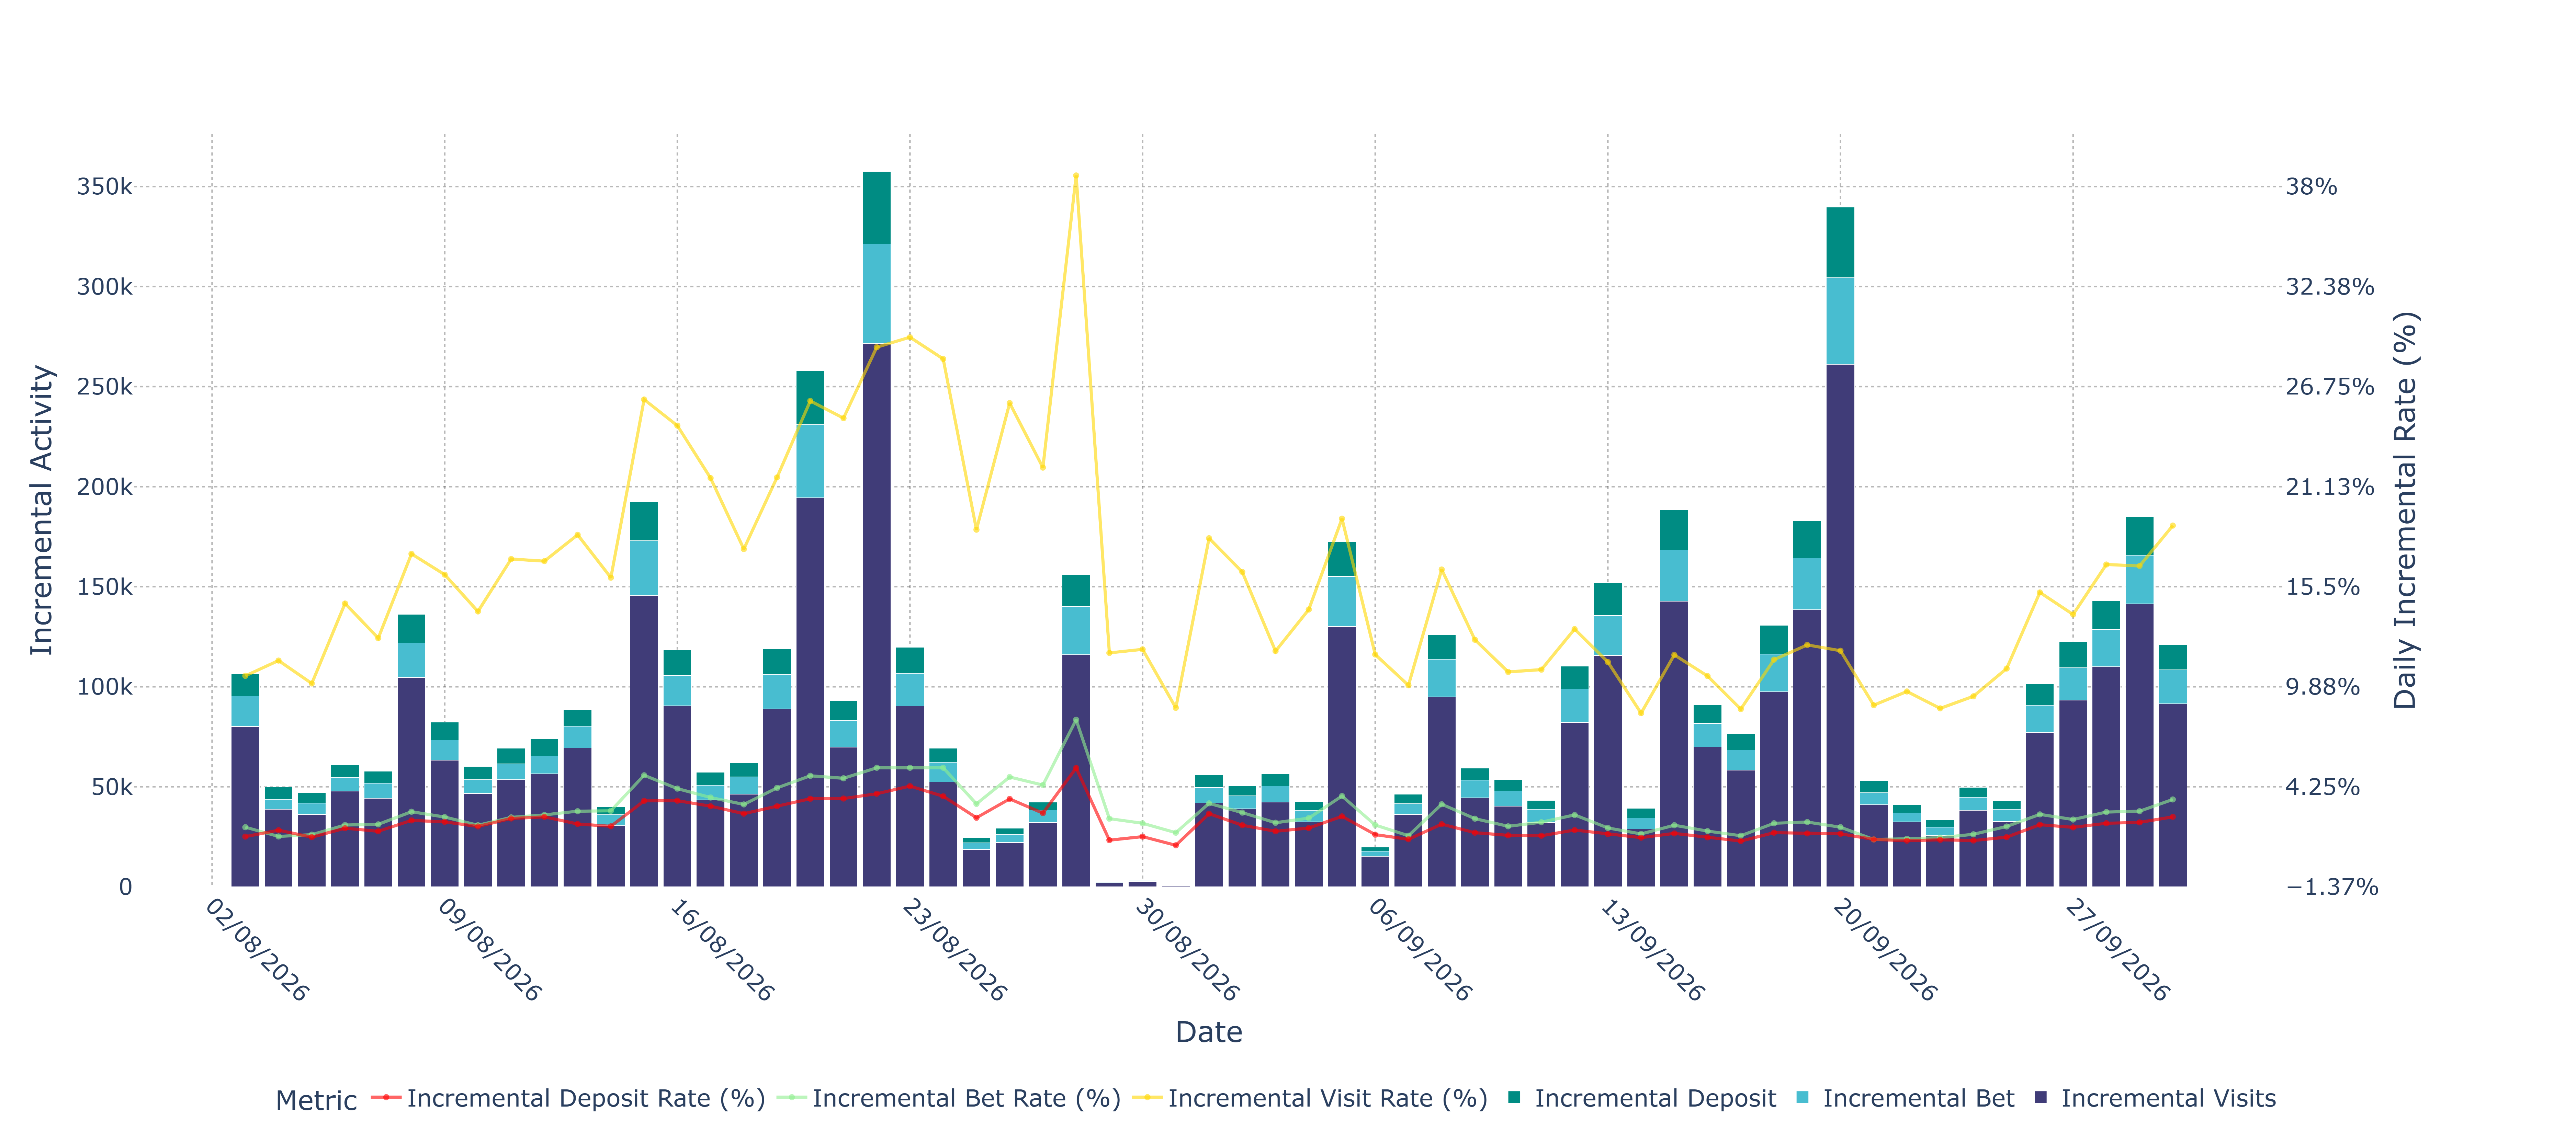

In [31]:
# Documentation: Visualise daily volumes and rates. Original code follows unchanged.
# Bar colours
colors = {
    "Incremental Visits": "#403C78",   # Dark Purple
    "Incremental Bet": "#48BDD0",      # Cyan Blue
    "Incremental Deposit": "#008C83"   # Teal Green
}

# Line colours with alpha = 0.6
rate_colors = {
    "Incremental Visit Rate_Daily": "rgba(255, 215, 0, 0.6)",   # Gold
    "Incremental Bet Rate_Daily": "rgba(144, 238, 144, 0.6)",  # Light Green
    "Incremental Deposit Rate_Daily": "rgba(255, 0, 0, 0.6)"    # Red
}

rate_names = {
    "Incremental Visit Rate_Daily": "Incremental Visit Rate (%)",
    "Incremental Bet Rate_Daily": "Incremental Bet Rate (%)",
    "Incremental Deposit Rate_Daily": "Incremental Deposit Rate (%)"
}

# ==========================================
# 2. Create chart with secondary Y-axis
# ==========================================

fig = make_subplots(
    specs=[[{"secondary_y": True}]]
)

# Stacked bars - Left Y-axis
for metric, color in colors.items():
    fig.add_trace(
        go.Bar(
            x=incremental_summary["Date_Corrected"],
            y=incremental_summary[metric],
            name=metric,
            marker_color=color
        ),
        secondary_y=False
    )

# ==========================================
# 3. Daily incremental rates - Right Y-axis
# ==========================================

for metric, color in rate_colors.items():
    fig.add_trace(
        go.Scatter(
            x=incremental_summary["Date_Corrected"],
            y=incremental_summary[metric],
            mode="lines+markers",
            name=rate_names[metric],
            line=dict(color=color, width=3),
            marker=dict(size=6, color=color),
            hovertemplate=(
                "%{x|%d/%m/%Y}<br>"
                "%{y:.2f}%<extra>%{fullData.name}</extra>"
            )
        ),
        secondary_y=True
    )

# ==========================================
# 4. Formatting and title
# ==========================================

fig.update_layout(
    title=dict(
        # text="Football Daily Incremental Performance All Platforms and Campaigns",
        font=dict(size=36),
        x=0.5,
        xanchor="center"
    ),
    barmode="stack",
    template="plotly_white",
    width=2500,
    height=1100,
    bargap=0.15,
    font=dict(size=24),
    legend=dict(
        title=dict(
            text="Metric",
            font=dict(size=26)
        ),
        font=dict(size=23),
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.25
    ),
    margin=dict(
        l=130,
        r=150,
        t=130,
        b=200
    ),
    plot_bgcolor="white",
    paper_bgcolor="white"
)

# ==========================================
# 5. Left Y-axis - Incremental activity
# ==========================================

fig.update_yaxes(
    title_text="Incremental Activity",
    title_font=dict(size=28),
    tickfont=dict(size=22),
    showgrid=True,
    gridcolor="rgba(80,80,80,0.40)",
    gridwidth=1.5,
    griddash="dot",
    zeroline=False,
    secondary_y=False
)

# ==========================================
# 6. Right Y-axis - Daily rates
# ==========================================

fig.update_yaxes(
    title_text="Daily Incremental Rate (%)",
    title_font=dict(size=28),
    tickfont=dict(size=22),
    ticksuffix="%",
    showgrid=False,
    zeroline=False,
    secondary_y=True
)

# ==========================================
# 7. X-axis
# ==========================================

fig.update_xaxes(
    title_text="Date",
    title_font=dict(size=28),
    tickfont=dict(size=22),
    tickformat="%d/%m/%Y",
    dtick=7 * 24 * 60 * 60 * 1000,
    tickangle=45,
    showgrid=True,
    gridcolor="rgba(80,80,80,0.40)",
    gridwidth=1.5,
    griddash="dot",
    zeroline=False
)

# ==========================================
# 8. Display static chart in Jupyter
# ==========================================

display(
    Image(
        fig.to_image(format="png", scale=3)
    )
)

# ==========================================
# 9. Save static PNG
# ==========================================

fig.write_image(
    "incremental_campaign_performance.png",
    scale=2
)

## Inspect the daily output

Displays the daily incremental performance dataframe for inspection.


In [26]:
# Documentation: Inspect the daily output. Original code follows unchanged.
incremental_summary

,Date_Corrected,Impressions,Visits,Incremental Visits,Incremental Deposit,Incremental Bet,Incremental Visit Rate_Daily,Incremental Deposit Rate_Daily,Incremental Bet Rate_Daily
0,2026-08-03,7.643009e+05,1.550184e+05,80138,11078,15153,10.49,1.45,1.98
1,2026-08-04,3.414398e+05,7.539440e+04,38756,6184,5002,11.35,1.81,1.46
2,2026-08-05,3.601564e+05,7.215726e+04,36224,5105,5616,10.06,1.42,1.56
3,2026-08-06,3.280533e+05,9.275985e+04,47766,6313,6904,14.56,1.92,2.10
4,2026-08-07,3.507602e+05,8.526862e+04,44219,6134,7496,12.61,1.75,2.14
5,2026-08-08,6.036822e+05,1.988125e+05,104710,14256,17228,17.35,2.36,2.85
6,2026-08-09,3.915677e+05,1.219199e+05,63343,8935,9978,16.18,2.28,2.55
7,2026-08-10,3.306914e+05,9.025786e+04,46646,6675,6898,14.11,2.02,2.09
8,2026-08-11,3.139003e+05,1.035228e+05,53549,7764,7938,17.06,2.47,2.53
9,2026-08-12,3.339279e+05,1.098892e+05,56558,8538,8930,16.94,2.56,2.67


# Week Day Summary

Campaign performance was assessed by aggregating advertising impressions and incremental customer activity across each weekday within the selected August and September reporting period. Incremental visit, bet and deposit rates were calculated relative to advertising impressions, then averaged across the seven weekdays to provide a consistent measure of typical weekday performance for each month.

## Calculate rates by month and weekday

Aggregates each month’s Mondays, Tuesdays, etc. across the selected dates, then divides incremental activity by corresponding impressions.


In [32]:
# Documentation: Calculate rates by month and weekday. Original code follows unchanged.


daily_summary = (
    df_clean
    .groupby(["Month_Label", "Day"], as_index=False)
    .agg({
        "Impressions": "sum",
        "Incremental Visits": "sum",
        "Incremental Bet": "sum",
        "Incremental Deposit": "sum"
    })
)


# Recalculate daily incremental rates
daily_summary["Incremental Visit Rate"] = (
    daily_summary["Incremental Visits"]
    / daily_summary["Impressions"] * 100
)

daily_summary["Incremental Bet Rate"] = (
    daily_summary["Incremental Bet"]
    / daily_summary["Impressions"] * 100
)

daily_summary["Incremental Deposit Rate"] = (
    daily_summary["Incremental Deposit"]
    / daily_summary["Impressions"] * 100
)

# Round results
rate_columns = [
    "Incremental Visit Rate",
    "Incremental Bet Rate",
    "Incremental Deposit Rate"
]

daily_summary[rate_columns] = (
    daily_summary[rate_columns].round(3)
)

display(daily_summary)

,Month_Label,Day,Impressions,Incremental Visits,Incremental Bet,Incremental Deposit,Incremental Visit Rate,Incremental Bet Rate,Incremental Deposit Rate
0,August,Friday,1.131188e+06,252684.26654,48477.80248,34986.86809,22.338,4.286,3.093
1,August,Monday,7.219365e+05,144343.84373,24227.41606,19633.73081,19.994,3.356,2.720
2,August,Saturday,2.117941e+06,523830.88304,94898.28152,70059.83059,24.733,4.481,3.308
3,August,Sunday,1.775509e+06,317250.60225,55154.37611,45089.77346,17.868,3.106,2.540
4,August,Thursday,1.601606e+06,342665.69017,60513.00318,45660.22050,21.395,3.778,2.851
5,August,Tuesday,1.088676e+06,184978.10292,30785.41955,27197.90786,16.991,2.828,2.498
6,August,Wednesday,1.188727e+06,194057.80487,33829.03973,28366.14626,16.325,2.846,2.386
7,September,Friday,1.904021e+06,235618.92893,44658.31981,33582.81676,12.375,2.345,1.764
8,September,Monday,1.829536e+06,216225.92911,35531.05910,29997.39833,11.819,1.942,1.640
9,September,Saturday,2.939343e+06,427806.03463,81251.02615,58073.66463,14.554,2.764,1.976


## Calculate equally weighted weekday averages

Calculates the simple average of available weekday-level rates for each month. Each weekday receives the same weight regardless of impression volume; this is **not** the aggregate month-level rate.


In [38]:
# Documentation: Calculate equally weighted weekday averages. Original code follows unchanged.
# Calculate mean of the 7 weekday rates by month
monthly_summary = (
    daily_summary
    .groupby("Month_Label", as_index=False)
    .agg({
        "Incremental Visit Rate": "mean",
        "Incremental Bet Rate": "mean",
        "Incremental Deposit Rate": "mean"
    })
)

# Rename columns
monthly_summary = monthly_summary.rename(columns={
    "Incremental Visit Rate": "Mean Incremental Visit Rate (%)",
    "Incremental Bet Rate": "Mean Incremental Bet Rate (%)",
    "Incremental Deposit Rate": "Mean Incremental Deposit Rate (%)"
})

# Sort chronologically
month_order = ["July", "August", "September"]

monthly_summary["Month_Label"] = pd.Categorical(
    monthly_summary["Month_Label"],
    categories=month_order,
    ordered=True
)

monthly_summary = (
    monthly_summary
    .sort_values("Month_Label")
    .reset_index(drop=True)
    .round(3)
)

display(monthly_summary)

,Month_Label,Mean Incremental Visit Rate (%),Mean Incremental Bet Rate (%),Mean Incremental Deposit Rate (%)
0,August,19.949,3.526,2.771
1,September,12.532,2.243,1.724


## Export weekday-averaged monthly rates

Writes the existing month-level mean of weekday rates to Excel.


In [28]:
# Documentation: Export weekday-averaged monthly rates. Original code follows unchanged.
# Export
monthly_summary.to_excel(
    "football_monthly_mean_incremental_rate_day.xlsx",
    index=False
)

# Metrics per Date

- Data Aggregation: Groups campaign data by month and weekday (Monday–Sunday).
- Metric Calculation: Sums impressions, incremental visits, bets and deposits.
- Incremental Rates: Calculates each incremental metric as a percentage of impressions.
- Monthly Comparison: Compares August and September 2026 performance.
- Visualisation: Creates grouped bar charts showing incremental rates by weekday.
- Performance Insights: Identifies the strongest and weakest performing weekdays.



Output: Exports a high-resolution PNG for stakeholder reporting.

## Compare incremental rates by weekday

Reaggregates data by month and weekday, handles zero impressions with missing rates, and plots grouped bars for the selected months.


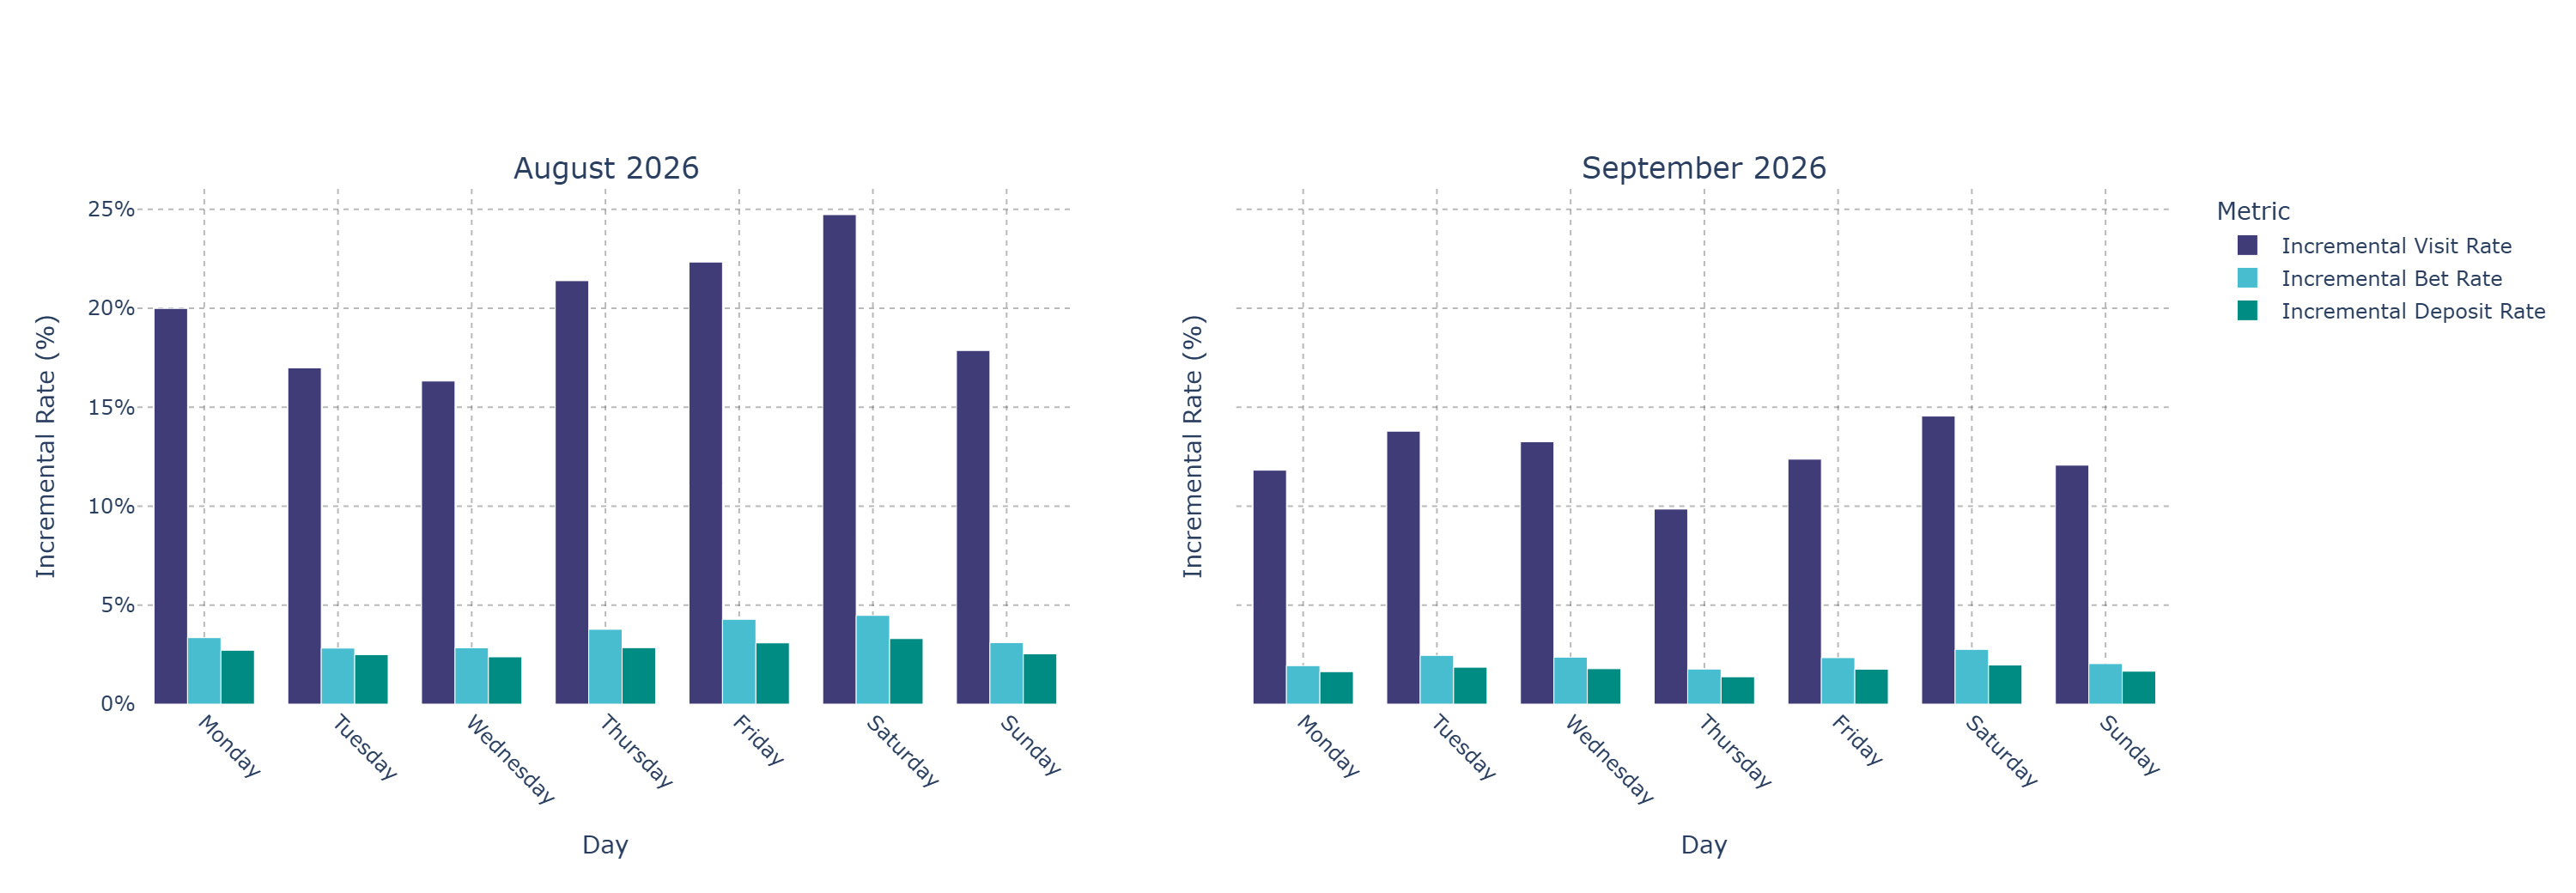

In [39]:
# Documentation: Compare incremental rates by weekday. Original code follows unchanged.
weekday_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
month_order = ["August","September"]

daily_summary = (
    df_clean.groupby(["Month_Label","Day"], as_index=False)
    .agg({
        "Impressions":"sum",
        "Incremental Visits":"sum",
        "Incremental Bet":"sum",
        "Incremental Deposit":"sum"
    })
)

daily_summary["Incremental Visit Rate"] = np.where(
    daily_summary["Impressions"] > 0,
    daily_summary["Incremental Visits"] / daily_summary["Impressions"] * 100,
    np.nan
)
daily_summary["Incremental Bet Rate"] = np.where(
    daily_summary["Impressions"] > 0,
    daily_summary["Incremental Bet"] / daily_summary["Impressions"] * 100,
    np.nan
)
daily_summary["Incremental Deposit Rate"] = np.where(
    daily_summary["Impressions"] > 0,
    daily_summary["Incremental Deposit"] / daily_summary["Impressions"] * 100,
    np.nan
)

fig = px.bar(
    daily_summary,
    x="Day",
    y=[
        "Incremental Visit Rate",
        "Incremental Bet Rate",
        "Incremental Deposit Rate"
    ],
    facet_col="Month_Label",
    facet_col_spacing=0.08,
    barmode="group",
    category_orders={"Day": weekday_order, "Month_Label": month_order},
    color_discrete_sequence=[
        "#403C78",  # Dark Purple - Visits
        "#48BDD0",  # Cyan Blue - Bets
        "#008C83"   # Teal Green - Deposits
    ],
    labels={"value":"Incremental Rate (%)", "variable":"Metric"}
)

fig.update_layout(
    template="plotly_white",
    width=1500,
    height=520,
    title=dict(
        # text="Football Incremental Performance by Weekday and Month",
        x=0.5,
        xanchor="center",
        font=dict(size=22)
    ),
    legend_title="Metric",
    bargap=0.25,
    margin=dict(l=80, r=60, t=110, b=110),
    plot_bgcolor="white",
    paper_bgcolor="white"
)

fig.update_xaxes(
    title_text="Day",
    tickangle=45,
    showgrid=True,
    gridcolor="rgba(80,80,80,0.40)",
    gridwidth=1,
    griddash="dot",
    zeroline=False
)

fig.update_yaxes(
    title_text="Incremental Rate (%)",
    ticksuffix="%",
    showgrid=True,
    gridcolor="rgba(80,80,80,0.40)",
    gridwidth=1,
    griddash="dot",
    zeroline=False
)

fig.for_each_annotation(
    lambda a: a.update(
        text=f"{a.text.split('=')[-1]} 2026",
        font=dict(size=17)
    )
)

display(Image(fig.to_image(format="png", scale=2)))
fig.write_image("vegas_incremental_performance.png", scale=2)


# Monthly Campaign Performance (Average)

## Calculate monthly performance by campaign

Aggregates by campaign and month, counts distinct active calendar days, and computes incremental visits, bets and deposits per 100 impressions.


In [40]:
# Documentation: Calculate monthly performance by campaign. Original code follows unchanged.
# Define chronological month order
month_order = ["August", "September"]

# Group by Campaign and Month, including duration
monthly_campaign_summary = (
    df_clean
    .groupby(["Campaign", "Month_Label"], as_index=False)
    .agg(
        **{
            "Duration (Days)": ("Date_Corrected", "nunique"),
            "Impressions": ("Impressions", "sum"),
            "Incremental Visits": ("Incremental Visits", "sum"),
            "Incremental Bet": ("Incremental Bet", "sum"),
            "Incremental Deposit": ("Incremental Deposit", "sum")
        }
    )
)

# Set chronological month ordering
monthly_campaign_summary["Month_Label"] = pd.Categorical(
    monthly_campaign_summary["Month_Label"],
    categories=month_order,
    ordered=True
)

# Sort by Campaign and Month
monthly_campaign_summary = (
    monthly_campaign_summary
    .sort_values(["Campaign", "Month_Label"])
    .reset_index(drop=True)
)

# Recalculate incremental rates
impressions = monthly_campaign_summary["Impressions"].replace(0, np.nan)

monthly_campaign_summary["Incremental Visit Rate"] = (
    monthly_campaign_summary["Incremental Visits"] / impressions * 100
)

monthly_campaign_summary["Incremental Bet Rate"] = (
    monthly_campaign_summary["Incremental Bet"] / impressions * 100
)

monthly_campaign_summary["Incremental Deposit Rate"] = (
    monthly_campaign_summary["Incremental Deposit"] / impressions * 100
)

# Round rates
rate_columns = [
    "Incremental Visit Rate",
    "Incremental Bet Rate",
    "Incremental Deposit Rate"
]

monthly_campaign_summary[rate_columns] = (
    monthly_campaign_summary[rate_columns].round(3)
)

# Display results
display(monthly_campaign_summary)


,Campaign,Month_Label,Duration (Days),Impressions,Incremental Visits,Incremental Bet,Incremental Deposit,Incremental Visit Rate,Incremental Bet Rate,Incremental Deposit Rate
0,NBTB New Season,September,29,1.726797e+07,2.179834e+06,389378.44125,298873.03363,12.624,2.255,1.731
1,New Season Launch,August,29,9.625584e+06,1.959811e+06,347885.33863,270994.47757,20.360,3.614,2.815
2,New Season Launch,September,7,2.751606e+05,4.735441e+04,8445.00089,6740.34429,17.210,3.069,2.450


## Format reporting values

Adds compact K/M presentation strings for selected campaign measures while retaining numerical measures in the table.


In [31]:
# Documentation: Format reporting values. Original code follows unchanged.
# Format large numbers into M and K
def format_number(value):
    if pd.isna(value):
        return "-"
    if abs(value) >= 1_000_000:
        return f"{value / 1_000_000:.2f}M"
    elif abs(value) >= 1_000:
        return f"{value / 1_000:.1f}K"
    return f"{value:,.0f}"

# Columns to format
metric_columns = [
    "Impressions",
    "Incremental Visits",
    "Incremental Bet",
    "Incremental Deposit"
]

# Format for display without modifying underlying values
display(
    monthly_campaign_summary.style.format({
        col: format_number for col in metric_columns
    })
)

,Campaign,Month_Label,Duration (Days),Impressions,Incremental Visits,Incremental Bet,Incremental Deposit,Incremental Visit Rate,Incremental Bet Rate,Incremental Deposit Rate
0,NBTB New Season,September,29,17.27M,2.18M,389.4K,298.9K,12.624000,2.255000,1.731000
1,New Season Launch,August,29,11.77M,3.09M,569.9K,421.4K,26.203000,4.840000,3.579000
2,New Season Launch,September,7,275.2K,47.4K,8.4K,6.7K,17.210000,3.069000,2.450000


## Export monthly campaign metrics

Saves the campaign-level volume/rate summary as an Excel file under the original hard-coded filename.


In [32]:
# Documentation: Export monthly campaign metrics. Original code follows unchanged.
# Export
monthly_campaign_summary.to_excel(
    "football_Campaign_Monthly_Summary_Rates.xlsx",
    index=False
)

## Visualise campaign performance as heatmaps

Pivots campaign-month rates and renders separate heatmaps for visits, bets and deposits. Missing campaign-month combinations appear as dashes.


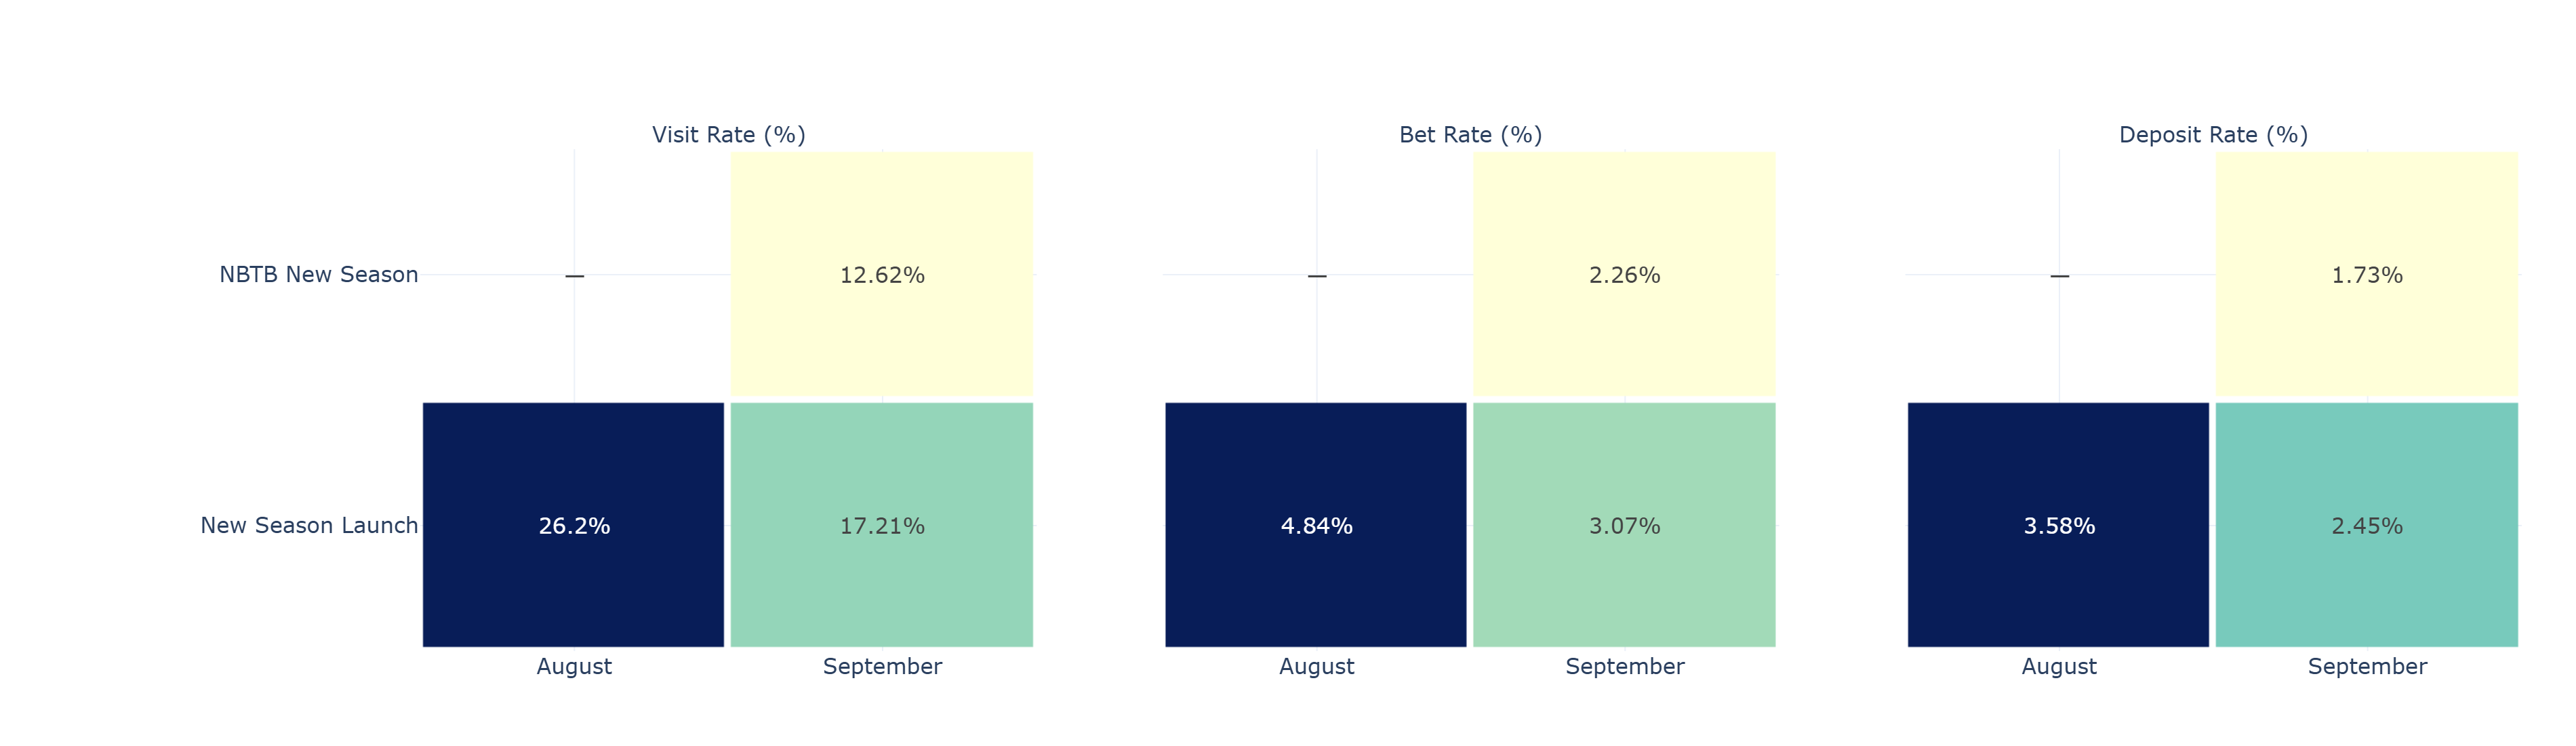

In [33]:
# Documentation: Visualise campaign performance as heatmaps. Original code follows unchanged.
month_order = ["August", "September"]

metrics = [
    "Incremental Visit Rate",
    "Incremental Bet Rate",
    "Incremental Deposit Rate"
]

titles = [
    "Visit Rate (%)",
    "Bet Rate (%)",
    "Deposit Rate (%)"
]

# Consistent campaign order
campaign_order = sorted(
    monthly_campaign_summary["Campaign"].dropna().unique()
)

fig = make_subplots(
    rows=1,
    cols=3,
    subplot_titles=titles,
    horizontal_spacing=0.06
)

for i, metric in enumerate(metrics, start=1):

    pivot = (
        monthly_campaign_summary
        .pivot(
            index="Campaign",
            columns="Month_Label",
            values=metric
        )
        .reindex(
            index=campaign_order,
            columns=month_order
        )
    )

    values = pivot.to_numpy(dtype=float)

    # Display missing observations as dashes
    labels = np.where(
        pd.isna(values),
        "—",
        np.round(values, 2).astype(str) + "%"
    )

    fig.add_trace(
        go.Heatmap(
            z=values,
            x=month_order,
            y=campaign_order,
            text=labels,
            texttemplate="%{text}",
            textfont=dict(size=16),
            colorscale="YlGnBu",
            showscale=False,
            xgap=5,
            ygap=5,
            hovertemplate=(
                "Campaign: %{y}<br>"
                "Month: %{x}<br>"
                "Rate: %{z:.2f}%<extra></extra>"
            )
        ),
        row=1,
        col=i
    )

fig.update_layout(
    title=dict(
        ## text="Monthly Incremental Campaign Performance",
        x=0.5,
        xanchor="center",
        font=dict(size=30)
    ),
    width=1900,
    height=550,
    template="plotly_white",
    font=dict(size=16),
    margin=dict(
        l=310,
        r=40,
        t=110,
        b=70
    ),
    paper_bgcolor="white"
)

# Show campaign labels only on first panel
for i in [2, 3]:
    fig.update_yaxes(
        showticklabels=False,
        row=1,
        col=i
    )

fig.update_yaxes(
    autorange="reversed"
)

display(Image(fig.to_image(format="png", scale=2)))